In [38]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [39]:
df = pd.read_csv("/content/bank-churn.csv", low_memory=False)
crudo = df

In [40]:
#comprobamos que se haya cargado bien
# Le cambiamos la estructura y el estilo para que se vea más prolijo
print(f"Dataset cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas\n")

display(df.head().style
    .set_properties(**{
        'text-align': 'center',
        'border': '1px solid #ddd',
        'padding': '6px 12px',
        'font-size': '13px',
        'color': 'black'
    })
    .set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#2c3e50'),
            ('color', 'white'),
            ('text-align', 'center'),
            ('padding', '8px 12px'),
            ('font-size', '13px')
        ]},
        {'selector': 'tr:nth-child(even)', 'props': [
            ('background-color', '#f2f2f2'),
            ('color', 'black')
        ]},
        {'selector': 'tr:nth-child(odd)', 'props': [
            ('background-color', '#ffffff'),
            ('color', 'black')
        ]},
        {'selector': 'tr:hover', 'props': [
            ('background-color', '#dce9f5'),
            ('color', 'black')
        ]},
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'),
            ('font-size', '14px'),
            ('font-weight', 'bold'),
            ('color', 'black')
        ]}
    ])
    .format(precision=2)
    .set_caption("Vista previa del dataset — primeras 5 filas")
)

Dataset cargado: 175,028 filas × 25 columnas



,Surname,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Surname_tfidf_0,Surname_tfidf_1,Surname_tfidf_2,Surname_tfidf_3,Surname_tfidf_4,France,Germany,Spain,Female,Male,Mem__no__Products,Cred_Bal_Sal,Bal_sal,Tenure_Age,Age_Tenure_product
0,2023,668.00,33.00,3.00,0.00,2.00,1,0,181449.97,0,"-3.124.436.679,76","-460.594.640,32","13.351.443.755,82","-6.116.396.019,04","6.694.577.725,07",1,0,0,0,1,0.00,0.0,0.0,"9.090.909.090.909.090,00",99.00
1,2024,627.00,33.00,1.00,0.00,2.00,1,1,49503.5,0,"481.338.256,69","838.931.547,32","-11.828.148.560,09","7.812.514.313,22","1.663.329.080,86",1,0,0,0,1,2.00,0.0,0.0,"30.303.030.303.030.300,00",33.00
2,1236,678.00,40.00,10.00,0.00,2.00,1,0,184866.69,0,"-3.447.294.172.650.730,00","-2.025.033.659.055.650,00","-10.280.719.705.962.700,00","-938.715.514.665.035,00","15.068.643.143.363.400,00",1,0,0,0,1,0.00,0.0,0.0,0.25,400.00
3,1362,581.00,34.00,2.00,148882.54,1.00,1,1,84560.88,0,"-72.209.360.028,78","-10.461.631.817.033.800,00","131.291.330.459.128,00","846.300.277.850.006,00","16.075.843.065.996.200,00",1,0,0,0,1,1.00,"10.229.405.812.711.500,00","17.606.550.452.171.200,00","58.823.529.411.764.700,00",68.00
4,491,716.00,33.00,5.00,0.00,2.00,1,1,15068.83,0,"-1.037.134.935,85","-545.133.813,64","498.455.946,81","-1.568.877.112,96","18.489.187.336,37",0,0,1,0,1,2.00,0.0,0.0,"15.151.515.151.515.100,00",165.00


In [41]:
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

# Estilo de los gráficos
AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#8a8984'
COLORES_CLASE = {0: AZUL, 1: NARANJA}          # 0 = se queda, 1 = se va
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'axes.titleweight': 'bold', 'axes.titlesize': 11,
})
SEMILLA = 42
os.makedirs('src', exist_ok=True)

In [42]:
#calidad de los datos y que falta
calidad = pd.DataFrame({
    'tipo': crudo.dtypes.astype(str),
    'faltantes': crudo.isna().sum(),
    'valores_distintos': crudo.nunique(),
    'ejemplo': crudo.iloc[0],
})
calidad

,tipo,faltantes,valores_distintos,ejemplo
Surname,int64,0,2932,2023
CreditScore,float64,0,460,668.000
Age,float64,0,73,33.000
Tenure,float64,0,11,3.000
Balance,float64,0,30239,0.000
NumOfProducts,float64,0,4,2.000
HasCrCard,int64,0,2,1
IsActiveMember,int64,0,2,0
EstimatedSalary,object,0,55581,181449.97
Exited,int64,0,2,0


In [43]:
#limpieza de la base de datos
COLUMNAS_ORIGINALES = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
                       'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

def limpiar(crudo: pd.DataFrame) -> pd.DataFrame:
    df = crudo.copy()
    df['EstimatedSalary'] = pd.to_numeric(df['EstimatedSalary'], errors='coerce')
    df['Geography'] = np.select([df['France'] == 1, df['Germany'] == 1, df['Spain'] == 1],
                                ['France', 'Germany', 'Spain'], default=None)
    df['Gender'] = np.where(df['Female'] == 1, 'Female', 'Male')
    df = df[['CreditScore', 'Geography', 'Gender'] + COLUMNAS_ORIGINALES[1:]]
    df = df.dropna()
    df = df.drop_duplicates()
    for col in ['Tenure', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Exited']:
        df[col] = df[col].astype(int)
    return df.reset_index(drop=True)

datos = limpiar(crudo)
print(f'Registros originales: {len(crudo):,}')
print(f'Registros después de la limpieza: {len(datos):,} ({len(crudo) - len(datos)} eliminados)')
datos.head()

Registros originales: 175,028
Registros después de la limpieza: 174,457 (571 eliminados)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,668.000,France,Male,33.000,3,0.000,2,1,0,"181,449.970",0
1,627.000,France,Male,33.000,1,0.000,2,1,1,"49,503.500",0
2,678.000,France,Male,40.000,10,0.000,2,1,0,"184,866.690",0
3,581.000,France,Male,34.000,2,"148,882.540",1,1,1,"84,560.880",0
4,716.000,Spain,Male,33.000,5,0.000,2,1,1,"15,068.830",0


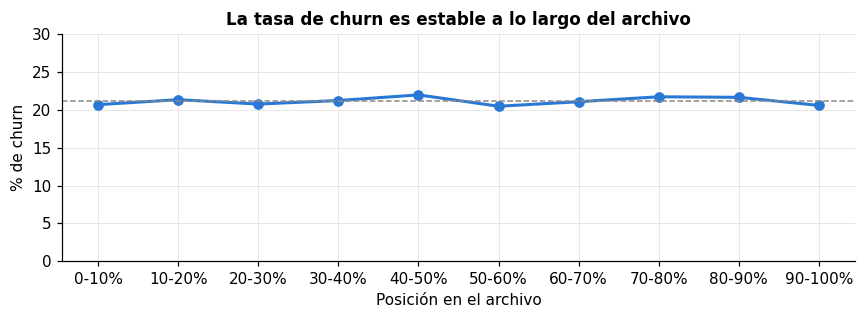

,0-10%,10-20%,20-30%,30-40%,40-50%,50-60%,60-70%,70-80%,80-90%,90-100%
% churn,20.700,21.300,20.800,21.200,22.000,20.500,21.100,21.700,21.700,20.600


In [44]:
#lote de datos
bloques = pd.qcut(datos.index, 10, labels=[f'{i*10}-{i*10+10}%' for i in range(10)])
tasa_por_bloque = datos.groupby(bloques, observed=True)['Exited'].mean()

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(tasa_por_bloque.index.astype(str), tasa_por_bloque.values * 100, color=AZUL, lw=2, marker='o', ms=6)
ax.axhline(datos['Exited'].mean() * 100, color=GRIS, ls='--', lw=1)
ax.set_ylim(0, 30); ax.set_ylabel('% de churn'); ax.set_xlabel('Posición en el archivo')
ax.set_title('La tasa de churn es estable a lo largo del archivo')
plt.tight_layout(); plt.show()
tasa_por_bloque.mul(100).round(1).to_frame('% churn').T

In [45]:
corte = int(len(datos) * 0.85)
desarrollo = datos.iloc[:corte].copy()
produccion = datos.iloc[corte:].copy()

train, test = train_test_split(desarrollo, test_size=0.20, stratify=desarrollo['Exited'],
                               random_state=SEMILLA)

resumen = pd.DataFrame({
    'registros': [len(train), len(test), len(produccion)],
    '% del total': [len(train) / len(datos) * 100, len(test) / len(datos) * 100, len(produccion) / len(datos) * 100],
    '% churn': [train['Exited'].mean() * 100, test['Exited'].mean() * 100, produccion['Exited'].mean() * 100],
}, index=['Entrenamiento', 'Evaluación', 'Producción (reservado)'])
resumen

,registros,% del total,% churn
Entrenamiento,118630,68.000,21.184
Evaluación,29658,17.000,21.181
Producción (reservado),26169,15.000,20.975


In [46]:
os.makedirs('data', exist_ok=True)
train.to_csv('data/train.csv', index=False)
test.to_csv('data/test.csv', index=False)
produccion.to_csv('data/produccion.csv', index=False)
print('Guardados: data/train.csv, data/test.csv, data/produccion.csv')

Guardados: data/train.csv, data/test.csv, data/produccion.csv


Analisis exploratorio

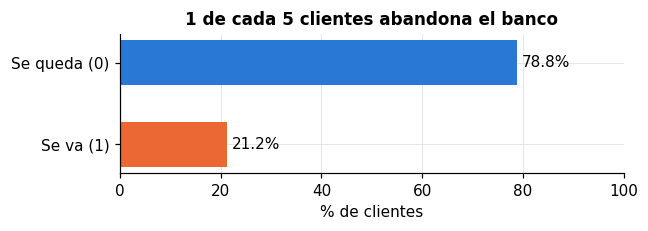

In [47]:
tasa = train['Exited'].mean()
fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(['Se va (1)', 'Se queda (0)'], [tasa * 100, (1 - tasa) * 100], color=[NARANJA, AZUL], height=0.55)
for i, v in enumerate([tasa * 100, (1 - tasa) * 100]):
    ax.text(v + 1, i, f'{v:.1f}%', va='center')
ax.set_xlim(0, 100); ax.set_xlabel('% de clientes')
ax.set_title('1 de cada 5 clientes abandona el banco')
plt.tight_layout(); plt.show()

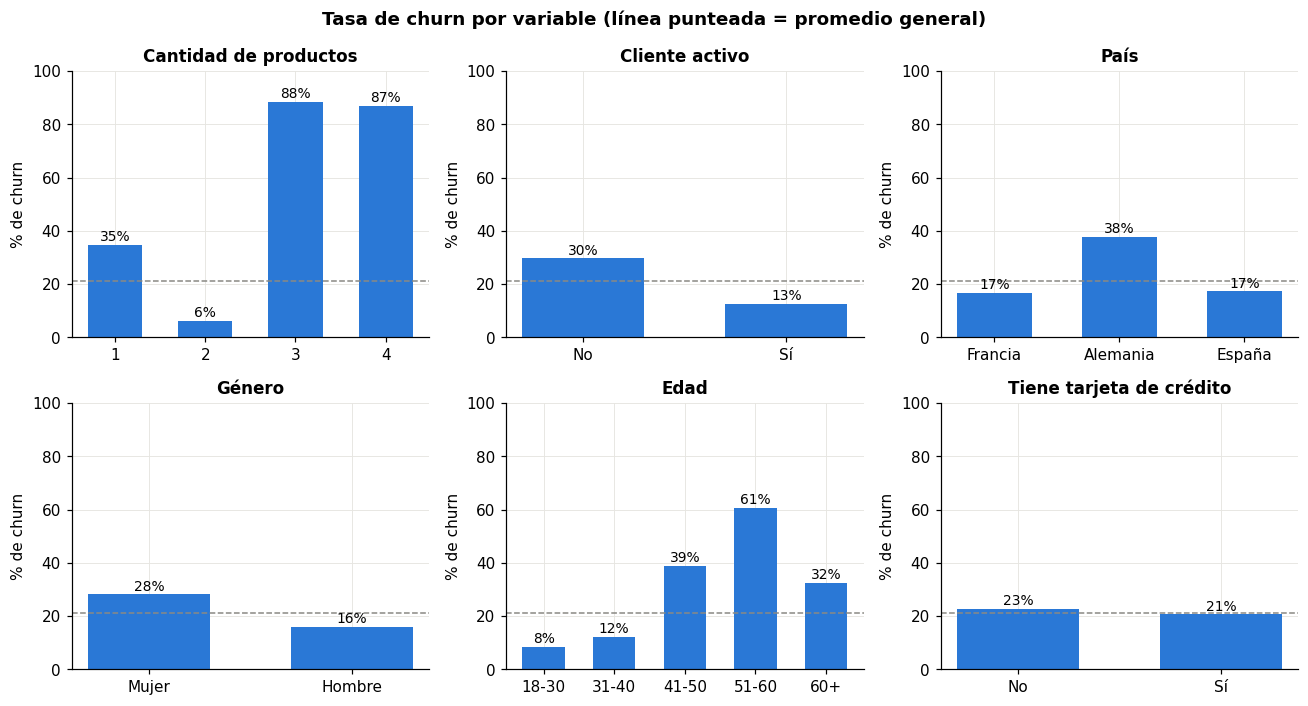

,tasa_churn,clientes
NumOfProducts,,
1,0.348,55472
2,0.061,60748
3,0.883,2076
4,0.868,334


In [48]:
def grafico_tasa(ax, serie, titulo, etiquetas=None):
    tasa = train.groupby(serie, observed=True)['Exited'].agg(['mean', 'size'])
    x = [str(i) for i in tasa.index] if etiquetas is None else etiquetas
    barras = ax.bar(x, tasa['mean'] * 100, color=AZUL, width=0.6)
    ax.axhline(train['Exited'].mean() * 100, color=GRIS, ls='--', lw=1)
    for b, (v, n) in zip(barras, tasa.values):
        ax.text(b.get_x() + b.get_width() / 2, v * 100 + 1.5, f'{v*100:.0f}%', ha='center', fontsize=9)
    ax.set_title(titulo); ax.set_ylim(0, 100); ax.set_ylabel('% de churn')
    return tasa

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
grafico_tasa(axes[0, 0], train['NumOfProducts'], 'Cantidad de productos')
grafico_tasa(axes[0, 1], train['IsActiveMember'], 'Cliente activo', ['No', 'Sí'])
grafico_tasa(axes[0, 2], train['Geography'], 'País', ['Francia', 'Alemania', 'España'])
grafico_tasa(axes[1, 0], train['Gender'], 'Género', ['Mujer', 'Hombre'])
grafico_tasa(axes[1, 1], pd.cut(train['Age'], [17, 30, 40, 50, 60, 100]), 'Edad',
             ['18-30', '31-40', '41-50', '51-60', '60+'])
grafico_tasa(axes[1, 2], train['HasCrCard'], 'Tiene tarjeta de crédito', ['No', 'Sí'])
fig.suptitle('Tasa de churn por variable (línea punteada = promedio general)', fontweight='bold')
plt.tight_layout(); plt.show()

train.groupby('NumOfProducts')['Exited'].agg(tasa_churn='mean', clientes='size')

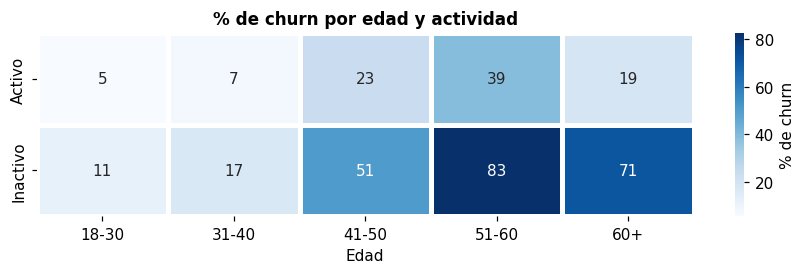

In [49]:
tabla = (train.assign(Edad=pd.cut(train['Age'], [17, 30, 40, 50, 60, 100],
                                  labels=['18-30', '31-40', '41-50', '51-60', '60+']),
                      Activo=train['IsActiveMember'].map({0: 'Inactivo', 1: 'Activo'}))
              .pivot_table(index='Activo', columns='Edad', values='Exited', aggfunc='mean', observed=True) * 100)

fig, ax = plt.subplots(figsize=(8, 2.6))
sns.heatmap(tabla, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% de churn'},
            linewidths=2, linecolor='white', ax=ax)
ax.set_xlabel('Edad'); ax.set_ylabel('')
ax.set_title('% de churn por edad y actividad')
plt.tight_layout(); plt.show()

In [50]:
saldo = (train.assign(SaldoCero=np.where(train['Balance'] == 0, 'Saldo = 0', 'Saldo > 0'))
              .groupby(['Geography', 'SaldoCero'])['Exited'].agg(['mean', 'size']))
saldo['mean'] *= 100
saldo.rename(columns={'mean': '% churn', 'size': 'clientes'})

% churn  clientes
Geography SaldoCero                   
France    Saldo = 0   16.140     46994
          Saldo > 0   17.667     20881
Germany   Saldo = 0   18.293        82
          Saldo > 0   37.875     24766
Spain     Saldo = 0   16.366     17457
          Saldo > 0   18.982      8450

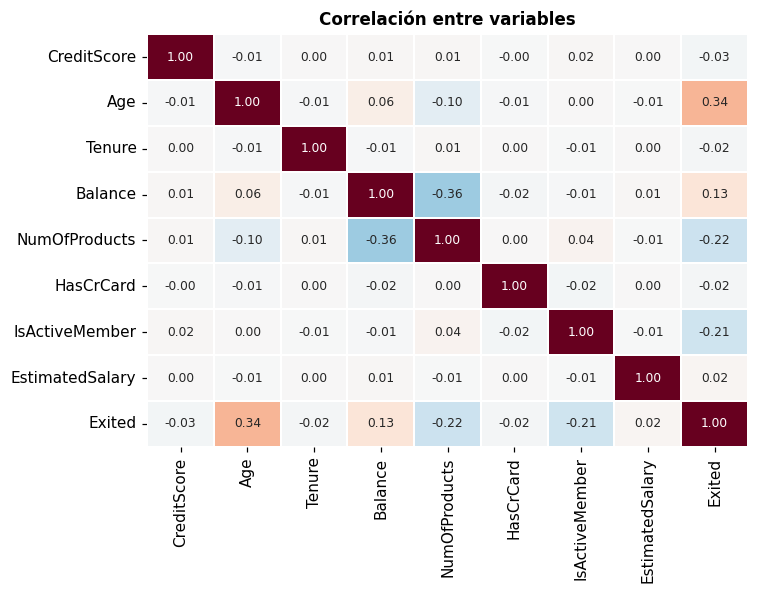

In [51]:
corr = train[['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
              'IsActiveMember', 'EstimatedSalary', 'Exited']].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=1, linecolor='white', cbar=False, ax=ax, annot_kws={'size': 8})
ax.set_title('Correlación entre variables')
plt.tight_layout(); plt.show()

In [52]:
%%writefile src/features.py
"""Transformaciones del modelo de churn. Las usan el entrenamiento, la app y el script por lotes."""
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Columnas que debe traer cada cliente (así llegan desde los sistemas del banco o la app)
COLUMNAS_ENTRADA = ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
                    'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
OBJETIVO = 'Exited'

NUMERICAS = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary',
             'SaldoSobreSalario', 'AntiguedadSobreEdad', 'EdadInactivo']
BINARIAS = ['HasCrCard', 'IsActiveMember', 'SaldoCero']
CATEGORICAS = ['Geography', 'Gender', 'Productos']


def construir_variables(X: pd.DataFrame) -> pd.DataFrame:
    """Agrega las variables construidas a partir de las columnas originales."""
    X = X[COLUMNAS_ENTRADA].copy()
    X['SaldoCero'] = (X['Balance'] == 0).astype(int)
    X['SaldoSobreSalario'] = X['Balance'] / X['EstimatedSalary'].clip(lower=1)
    X['AntiguedadSobreEdad'] = X['Tenure'] / X['Age']
    X['EdadInactivo'] = X['Age'] * (1 - X['IsActiveMember'])
    X['Productos'] = np.where(X['NumOfProducts'] >= 3, '3+', X['NumOfProducts'].astype(int).astype(str))
    return X


def nombres_variables(transformador, columnas_entrada):
    """Nombres de las columnas que devuelve construir_variables (los usa scikit-learn)."""
    return np.array(COLUMNAS_ENTRADA + ['SaldoCero', 'SaldoSobreSalario', 'AntiguedadSobreEdad',
                                        'EdadInactivo', 'Productos'])


def crear_preprocesamiento() -> Pipeline:
    """Pipeline de transformaciones: construcción de variables + imputación + escalado + codificación."""
    columnas = ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),
                          ('escalar', StandardScaler())]), NUMERICAS),
        ('bin', SimpleImputer(strategy='most_frequent'), BINARIAS),
        ('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                          ('codificar', OneHotEncoder(handle_unknown='ignore'))]), CATEGORICAS),
    ], verbose_feature_names_out=False)
    return Pipeline([
        ('variables', FunctionTransformer(construir_variables, feature_names_out=nombres_variables)),
        ('columnas', columnas),
    ])

Overwriting src/features.py


Pruebas de pipeline

In [53]:
os.makedirs('src', exist_ok=True)
sys.path.insert(0, os.path.abspath('src'))
from features import crear_preprocesamiento, construir_variables, COLUMNAS_ENTRADA, OBJETIVO

X_train, y_train = train[COLUMNAS_ENTRADA], train[OBJETIVO]
X_test, y_test = test[COLUMNAS_ENTRADA], test[OBJETIVO]

preproceso = crear_preprocesamiento()
preproceso.fit(X_train)                       # aprende medianas, medias y categorías SOLO del entrenamiento
X_train_t = preproceso.transform(X_train)
X_test_t = preproceso.transform(X_test)

print('Entrada :', X_train.shape)
print('Salida  :', X_train_t.shape)
print('Variables que recibe el modelo:')
print(list(preproceso.get_feature_names_out()))

Entrada : (118630, 10)
Salida  : (118630, 19)
Variables que recibe el modelo:
['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary', 'SaldoSobreSalario', 'AntiguedadSobreEdad', 'EdadInactivo', 'HasCrCard', 'IsActiveMember', 'SaldoCero', 'Geography_France', 'Geography_Germany', 'Geography_Spain', 'Gender_Female', 'Gender_Male', 'Productos_1', 'Productos_2', 'Productos_3+']


In [54]:
nuevas = construir_variables(X_train).assign(Exited=y_train.values)
pd.concat([
    nuevas.groupby('Productos')['Exited'].mean().rename(lambda x: f'Productos = {x}'),
    nuevas.groupby('SaldoCero')['Exited'].mean().rename(lambda x: f'SaldoCero = {x}'),
]).mul(100).round(1).to_frame('% churn')

,% churn
Productos = 1,34.800
Productos = 2,6.100
Productos = 3+,88.100
SaldoCero = 0,27.100
SaldoCero = 1,16.200


In [55]:
cliente_nuevo = pd.DataFrame([{
    'CreditScore': 620, 'Geography': 'Germany', 'Gender': 'Female', 'Age': 52, 'Tenure': 3,
    'Balance': 110000.0, 'NumOfProducts': 1, 'HasCrCard': 1, 'IsActiveMember': 0,
    'EstimatedSalary': 85000.0,
}])
pd.DataFrame(preproceso.transform(cliente_nuevo), columns=preproceso.get_feature_names_out()).round(2)

,CreditScore,Age,Tenure,Balance,EstimatedSalary,SaldoSobreSalario,AntiguedadSobreEdad,EdadInactivo,HasCrCard,IsActiveMember,SaldoCero,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male,Productos_1,Productos_2,Productos_3+
0,-0.460,1.560,-0.720,0.870,-0.550,-0.010,-0.950,1.650,1.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.000


ENTRENAMIENTO DE MODELOS

In [56]:
import json, time
import joblib
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.calibration import calibration_curve
from scipy.stats import randint, uniform, loguniform

AQUA = '#1baf7a'
COLOR_MODELO = {'Regresión logística': GRIS, 'Random Forest': AQUA, 'Gradient Boosting': AZUL}

In [57]:
CAPACIDAD = 0.20   # proporción de la cartera que Retención puede contactar

def metricas_negocio(y, prob, capacidad=CAPACIDAD):
    y, prob = np.asarray(y), np.asarray(prob)
    n_contactos = int(round(len(y) * capacidad))
    orden = np.argsort(-prob, kind='stable')[:n_contactos]
    captura = y[orden].sum() / y.sum()
    acierto = y[orden].mean()
    return {'AUC': roc_auc_score(y, prob), 'Captura 20%': captura, 'Acierto lista 20%': acierto}

def evaluar(nombre, y, prob, capacidad=CAPACIDAD):
    return pd.Series(metricas_negocio(y, prob, capacidad), name=nombre)

In [58]:
regla_test = ((test['Age'] > 40) & (test['NumOfProducts'] == 1)).astype(int)
cobertura_regla = regla_test.mean()

lineas_base = pd.DataFrame({
    'Azar': {'Clientes contactados': CAPACIDAD,
             'Captura': CAPACIDAD,
             'Acierto de la lista': y_test.mean()},
    'Regla: >40 años y 1 producto': {'Clientes contactados': cobertura_regla,
             'Captura': y_test[regla_test == 1].sum() / y_test.sum(),
             'Acierto de la lista': y_test[regla_test == 1].mean()},
}).T
lineas_base.mul(100).round(1).astype(str).add('%')

,Clientes contactados,Captura,Acierto de la lista
Azar,20.0%,20.0%,21.2%
Regla: >40 años y 1 producto,18.5%,50.7%,58.1%


In [59]:
#esquema de validacion
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

muestra = train.groupby(OBJETIVO, group_keys=False).sample(frac=40_000 / len(train), random_state=SEMILLA)
X_muestra, y_muestra = muestra[COLUMNAS_ENTRADA], muestra[OBJETIVO]
print(f'Muestra para la búsqueda: {len(muestra):,} clientes, {y_muestra.mean():.1%} de churn')

def con_pipeline(modelo):
    return Pipeline([('preproceso', crear_preprocesamiento()), ('modelo', modelo)])

Muestra para la búsqueda: 40,000 clientes, 21.2% de churn


In [60]:
#modelo de referencia
busqueda_lr = RandomizedSearchCV(
    con_pipeline(LogisticRegression(max_iter=2000)),
    {'modelo__C': loguniform(1e-3, 1e2)},
    n_iter=10, scoring='roc_auc', cv=cv, random_state=SEMILLA, n_jobs=-1)
busqueda_lr.fit(X_muestra, y_muestra)
print(f"Mejor C: {busqueda_lr.best_params_['modelo__C']:.3f} | AUC en validación cruzada: {busqueda_lr.best_score_:.4f}")

Mejor C: 0.075 | AUC en validación cruzada: 0.8738


In [62]:
#random forest
espacio_rf = {
    'modelo__n_estimators': randint(150, 400),
    'modelo__max_depth': [8, 12, 16, None],
    'modelo__min_samples_leaf': randint(5, 60),
    'modelo__max_features': uniform(0.2, 0.6),
    'modelo__class_weight': [None, 'balanced'],
}
busqueda_rf = RandomizedSearchCV(
    con_pipeline(RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)),
    espacio_rf, n_iter=15, scoring='roc_auc', cv=cv, random_state=SEMILLA, n_jobs=1, verbose=0)

inicio = time.time()
busqueda_rf.fit(X_muestra, y_muestra)
print(f'Tiempo de búsqueda: {(time.time() - inicio) / 60:.1f} minutos')
print(f'AUC en validación cruzada: {busqueda_rf.best_score_:.4f}')
pd.Series({k.replace('modelo__', ''): str(v) if v is None else round(v, 3) if isinstance(v, float) else v
           for k, v in busqueda_rf.best_params_.items()}, dtype=object).to_frame('mejor valor')

Tiempo de búsqueda: 20.2 minutos
AUC en validación cruzada: 0.8858


,mejor valor
class_weight,None
max_depth,8
max_features,0.294
min_samples_leaf,23
n_estimators,364


In [63]:
#gardien boosting
espacio_gb = {
    'modelo__n_estimators': randint(100, 400),
    'modelo__learning_rate': loguniform(0.03, 0.2),
    'modelo__max_depth': randint(2, 6),
    'modelo__min_samples_leaf': randint(20, 200),
    'modelo__subsample': uniform(0.6, 0.4),
}
busqueda_gb = RandomizedSearchCV(
    con_pipeline(GradientBoostingClassifier(validation_fraction=0.1, n_iter_no_change=15, random_state=SEMILLA)),
    espacio_gb, n_iter=15, scoring='roc_auc', cv=cv, random_state=SEMILLA, n_jobs=-1)

inicio = time.time()
busqueda_gb.fit(X_muestra, y_muestra)
print(f'Tiempo de búsqueda: {(time.time() - inicio) / 60:.1f} minutos')
print(f'AUC en validación cruzada: {busqueda_gb.best_score_:.4f}')
pd.Series({k.replace('modelo__', ''): round(v, 3) if isinstance(v, float) else v
           for k, v in busqueda_gb.best_params_.items()}, dtype=object).to_frame('mejor valor')

Tiempo de búsqueda: 10.0 minutos
AUC en validación cruzada: 0.8877


,mejor valor
learning_rate,0.039
max_depth,4
min_samples_leaf,169
n_estimators,357
subsample,0.889


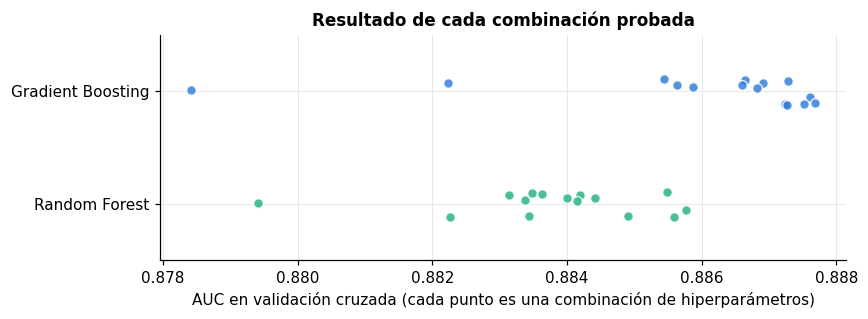

/tmp/ipykernel_14952/1730897066.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res.groupby('modelo', sort=False).apply(lambda g: g.loc[g['AUC'].idxmax(), 'desvío']).rename('desvío del mejor'))


,count,min,max,desvío del mejor
modelo,,,,
Random Forest,15.000,0.879,0.886,0.002
Gradient Boosting,15.000,0.878,0.888,0.003


In [64]:
#resultados
def resultados(busqueda, nombre):
    r = pd.DataFrame(busqueda.cv_results_)
    return pd.DataFrame({'modelo': nombre, 'AUC': r['mean_test_score'], 'desvío': r['std_test_score']})

res = pd.concat([resultados(busqueda_rf, 'Random Forest'), resultados(busqueda_gb, 'Gradient Boosting')])

fig, ax = plt.subplots(figsize=(8, 3))
for i, (nombre, grupo) in enumerate(res.groupby('modelo', sort=False)):
    ax.scatter(grupo['AUC'], np.full(len(grupo), i) + np.random.default_rng(0).uniform(-0.12, 0.12, len(grupo)),
               s=40, color=COLOR_MODELO[nombre], alpha=0.8, edgecolor='white', linewidth=1)
ax.set_yticks([0, 1]); ax.set_yticklabels(res['modelo'].unique())
ax.set_xlabel('AUC en validación cruzada (cada punto es una combinación de hiperparámetros)')
ax.set_title('Resultado de cada combinación probada'); ax.set_ylim(-0.5, 1.5)
plt.tight_layout(); plt.show()

res.groupby('modelo', sort=False)['AUC'].describe()[['count', 'min', 'max']].join(
    res.groupby('modelo', sort=False).apply(lambda g: g.loc[g['AUC'].idxmax(), 'desvío']).rename('desvío del mejor'))

In [65]:
#entrenamiento y evaluacion
modelos = {
    'Regresión logística': busqueda_lr.best_estimator_,
    'Random Forest': busqueda_rf.best_estimator_,
    'Gradient Boosting': busqueda_gb.best_estimator_,
}
prob_test, prob_train, tiempos = {}, {}, {}
for nombre, modelo in modelos.items():
    inicio = time.time()
    modelo.fit(X_train, y_train)
    tiempos[nombre] = time.time() - inicio
    prob_test[nombre] = modelo.predict_proba(X_test)[:, 1]
    prob_train[nombre] = modelo.predict_proba(X_train)[:, 1]

print(f"Árboles usados por Gradient Boosting tras la detención temprana: {modelos['Gradient Boosting'].named_steps['modelo'].n_estimators_}")
comparacion = pd.DataFrame([evaluar(n, y_test, p) for n, p in prob_test.items()])
comparacion['AUC entrenamiento'] = [roc_auc_score(y_train, prob_train[n]) for n in modelos]
comparacion['Segundos de entrenamiento'] = [tiempos[n] for n in modelos]

Árboles usados por Gradient Boosting tras la detención temprana: 245


In [66]:
#intervalos de confianza
rng = np.random.default_rng(SEMILLA)
yt = y_test.to_numpy()
muestras_boot = [rng.integers(0, len(yt), len(yt)) for _ in range(500)]

boot = {n: pd.DataFrame([metricas_negocio(yt[i], p[i]) for i in muestras_boot]) for n, p in prob_test.items()}

intervalos = pd.concat({n: b.quantile([0.025, 0.975]).T for n, b in boot.items()}, names=['modelo', 'métrica'])
intervalos.columns = ['límite inferior', 'límite superior']
intervalos.insert(0, 'valor', [comparacion.loc[n, m] for n, m in intervalos.index])
intervalos

valor  límite inferior  límite superior
modelo              métrica                                                   
Regresión logística AUC                0.874            0.869            0.879
                    Captura 20%        0.629            0.618            0.638
                    Acierto lista 20%  0.666            0.653            0.681
Random Forest       AUC                0.888            0.884            0.893
                    Captura 20%        0.641            0.630            0.650
                    Acierto lista 20%  0.679            0.664            0.694
Gradient Boosting   AUC                0.890            0.886            0.895
                    Captura 20%        0.646            0.636            0.656
                    Acierto lista 20%  0.685            0.671            0.699

In [67]:
diferencia = boot['Gradient Boosting'] - boot['Random Forest']
pd.DataFrame({
    'diferencia GB - RF': [comparacion.loc['Gradient Boosting', m] - comparacion.loc['Random Forest', m] for m in diferencia],
    'IC 95% inferior': diferencia.quantile(0.025), 'IC 95% superior': diferencia.quantile(0.975),
    '% de muestras en que GB gana': (diferencia > 0).mean() * 100,
}, index=diferencia.columns)

,diferencia GB - RF,IC 95% inferior,IC 95% superior,% de muestras en que GB gana
AUC,0.002,0.001,0.003,100.000
Captura 20%,0.005,0.002,0.009,99.600
Acierto lista 20%,0.006,0.002,0.009,99.600


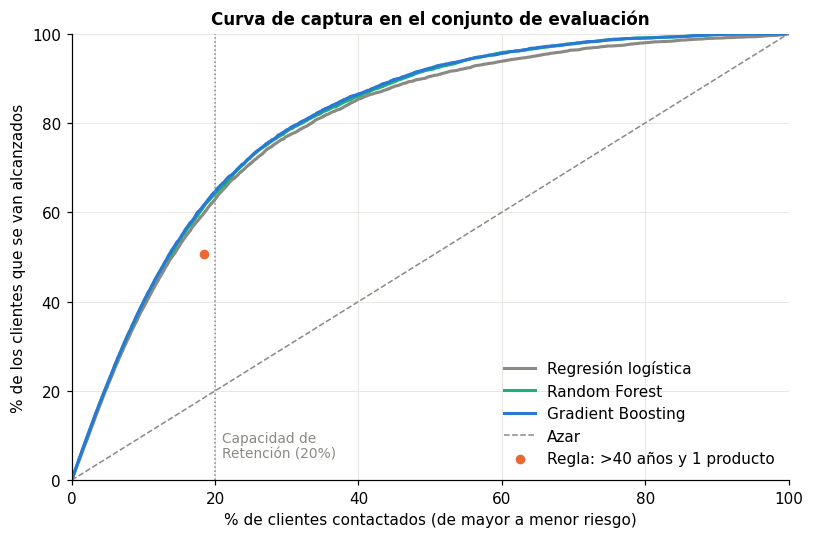

,Captura,Acierto de la lista
Regla: >40 años y 1 producto,50.700,58.100
Regresión logística,59.800,68.600
Random Forest,61.400,70.300
Gradient Boosting,61.700,70.700


In [68]:
def curva_captura(y, prob):
    y = np.asarray(y)
    orden = np.argsort(-np.asarray(prob), kind='stable')
    return np.arange(1, len(y) + 1) / len(y) * 100, np.cumsum(y[orden]) / y.sum() * 100

fig, ax = plt.subplots(figsize=(7.5, 5))
for nombre, p in prob_test.items():
    x, c = curva_captura(y_test, p)
    ax.plot(x, c, lw=2, color=COLOR_MODELO[nombre], label=nombre)
ax.plot([0, 100], [0, 100], color=GRIS, ls='--', lw=1, label='Azar')
ax.scatter(lineas_base.iloc[1, 0] * 100, lineas_base.iloc[1, 1] * 100, s=70, color=NARANJA, zorder=5,
           edgecolor='white', linewidth=2, label='Regla: >40 años y 1 producto')
ax.axvline(CAPACIDAD * 100, color=GRIS, lw=1, ls=':')
ax.text(CAPACIDAD * 100 + 1, 5, 'Capacidad de\nRetención (20%)', fontsize=9, color=GRIS)
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel('% de clientes contactados (de mayor a menor riesgo)')
ax.set_ylabel('% de los clientes que se van alcanzados')
ax.set_title('Curva de captura en el conjunto de evaluación')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

# Comparación justa con la regla: contactando la MISMA cantidad de clientes que selecciona la regla
pd.DataFrame([lineas_base.iloc[1, 1:].rename('Regla: >40 años y 1 producto')] +
             [pd.Series(metricas_negocio(y_test, p, cobertura_regla)).rename({'Captura 20%': 'Captura', 'Acierto lista 20%': 'Acierto de la lista'})[['Captura', 'Acierto de la lista']].rename(n)
              for n, p in prob_test.items()]).mul(100).round(1)

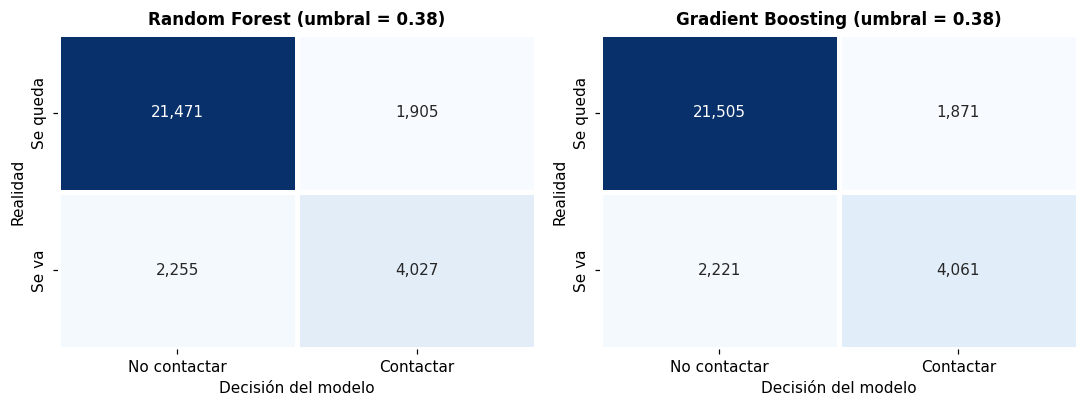

In [69]:
#analisid de errores
def marcar_contacto(prob, capacidad=CAPACIDAD):
    umbral = np.quantile(prob, 1 - capacidad)
    return (prob >= umbral).astype(int), umbral

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, nombre in zip(axes, ['Random Forest', 'Gradient Boosting']):
    pred, umbral = marcar_contacto(prob_test[nombre])
    mc = confusion_matrix(y_test, pred)
    sns.heatmap(mc, annot=np.array([[f'{v:,}' for v in fila] for fila in mc]), fmt='', cbar=False, cmap='Blues',
                linewidths=2, linecolor='white', ax=ax,
                xticklabels=['No contactar', 'Contactar'], yticklabels=['Se queda', 'Se va'])
    ax.set_title(f'{nombre} (umbral = {umbral:.2f})'); ax.set_xlabel('Decisión del modelo'); ax.set_ylabel('Realidad')
plt.tight_layout(); plt.show()

In [70]:
analisis = test.copy()
for nombre in ['Random Forest', 'Gradient Boosting']:
    analisis[nombre] = marcar_contacto(prob_test[nombre])[0]
analisis['Edad'] = pd.cut(analisis['Age'], [17, 30, 40, 50, 60, 100], labels=['18-30', '31-40', '41-50', '51-60', '60+'])
analisis['Productos'] = np.where(analisis['NumOfProducts'] >= 3, '3+', analisis['NumOfProducts'].astype(str))
analisis['Activo'] = analisis['IsActiveMember'].map({0: 'Inactivo', 1: 'Activo'})
analisis['País'] = analisis['Geography'].map({'France': 'Francia', 'Germany': 'Alemania', 'Spain': 'España'})

se_van = analisis[analisis[OBJETIVO] == 1]
filas = []
for variable in ['Productos', 'Edad', 'Activo', 'País']:
    g = se_van.groupby(variable, observed=True)
    filas.append(pd.DataFrame({
        'segmento': [f'{variable}: {v}' for v in g.size().index],
        'clientes que se van': g.size().values,
        'captura RF %': (g['Random Forest'].mean() * 100).values,
        'captura GB %': (g['Gradient Boosting'].mean() * 100).values,
    }))
captura_segmento = pd.concat(filas, ignore_index=True)
captura_segmento

,segmento,clientes que se van,captura RF %,captura GB %
0,Productos: 1,4857,68.170,68.993
1,Productos: 2,871,18.599,17.910
2,Productos: 3+,554,100.000,100.000
3,Edad: 18-30,423,8.038,14.421
4,Edad: 31-40,1822,31.065,33.644
5,Edad: 41-50,2604,81.490,79.954
6,Edad: 51-60,1219,92.043,93.027
7,Edad: 60+,214,85.514,79.907
8,Activo: Activo,1845,47.425,45.962
9,Activo: Inactivo,4437,71.039,72.414


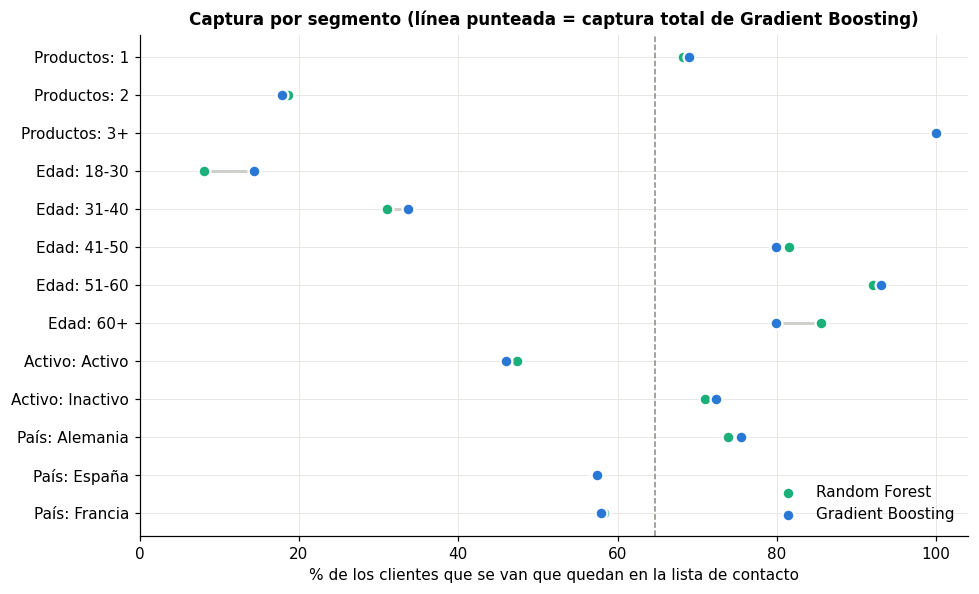

In [71]:
fig, ax = plt.subplots(figsize=(9, 5.5))
y_pos = np.arange(len(captura_segmento))[::-1]
ax.hlines(y_pos, captura_segmento['captura RF %'], captura_segmento['captura GB %'], color='#d0cfca', lw=2)
ax.scatter(captura_segmento['captura RF %'], y_pos, s=60, color=AQUA, label='Random Forest', zorder=3, edgecolor='white', linewidth=1.5)
ax.scatter(captura_segmento['captura GB %'], y_pos, s=60, color=AZUL, label='Gradient Boosting', zorder=3, edgecolor='white', linewidth=1.5)
ax.set_yticks(y_pos); ax.set_yticklabels(captura_segmento['segmento'])
ax.axvline(comparacion.loc['Gradient Boosting', 'Captura 20%'] * 100, color=GRIS, ls='--', lw=1)
ax.set_xlim(0, 104); ax.set_xlabel('% de los clientes que se van que quedan en la lista de contacto')
ax.set_title('Captura por segmento (línea punteada = captura total de Gradient Boosting)')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

In [72]:
gb = analisis.assign(grupo=np.select(
    [(analisis[OBJETIVO] == 1) & (analisis['Gradient Boosting'] == 1),
     (analisis[OBJETIVO] == 1) & (analisis['Gradient Boosting'] == 0),
     (analisis[OBJETIVO] == 0) & (analisis['Gradient Boosting'] == 1)],
    ['Se va y se detecta', 'Se va y NO se detecta (FN)', 'Contactado sin necesidad (FP)'], default='Se queda y no se contacta'))

perfil = gb.groupby('grupo').agg(
    clientes=('Age', 'size'), edad_media=('Age', 'mean'),
    pct_activos=('IsActiveMember', 'mean'), pct_2_productos=('NumOfProducts', lambda s: (s == 2).mean()),
    pct_alemania=('Geography', lambda s: (s == 'Germany').mean()), pct_mujeres=('Gender', lambda s: (s == 'Female').mean()),
    saldo_medio=('Balance', 'mean'))
for c in ['pct_activos', 'pct_2_productos', 'pct_alemania', 'pct_mujeres']:
    perfil[c] *= 100
perfil.loc[['Se va y se detecta', 'Se va y NO se detecta (FN)', 'Contactado sin necesidad (FP)', 'Se queda y no se contacta']]

,clientes,edad_media,pct_activos,pct_2_productos,pct_alemania,pct_mujeres,saldo_medio
grupo,,,,,,,
Se va y se detecta,4061,47.332,20.882,3.841,45.137,62.891,"69,886.851"
Se va y NO se detecta (FN),2221,37.625,44.890,32.193,26.700,45.340,"76,607.560"
Contactado sin necesidad (FP),1871,45.025,28.060,8.124,40.353,60.342,"70,487.631"
Se queda y no se contacta,21505,35.765,57.610,64.971,14.122,38.293,"49,638.286"


In [73]:
coinciden = pd.crosstab(analisis['Random Forest'].map({0: 'RF no contacta', 1: 'RF contacta'}),
                        analisis['Gradient Boosting'].map({0: 'GB no contacta', 1: 'GB contacta'}), margins=True, margins_name='Total')
coinciden

Gradient Boosting,GB contacta,GB no contacta,Total
Random Forest,,,
RF contacta,5669,263,5932
RF no contacta,263,23463,23726
Total,5932,23726,29658


In [74]:
solo_gb = analisis[(analisis['Gradient Boosting'] == 1) & (analisis['Random Forest'] == 0)]
solo_rf = analisis[(analisis['Gradient Boosting'] == 0) & (analisis['Random Forest'] == 1)]
pd.DataFrame({
    'clientes': [len(solo_gb), len(solo_rf)],
    '% que realmente se va': [solo_gb[OBJETIVO].mean() * 100, solo_rf[OBJETIVO].mean() * 100],
}, index=['Solo Gradient Boosting los contacta', 'Solo Random Forest los contacta'])

,clientes,% que realmente se va
Solo Gradient Boosting los contacta,263,44.487
Solo Random Forest los contacta,263,31.559


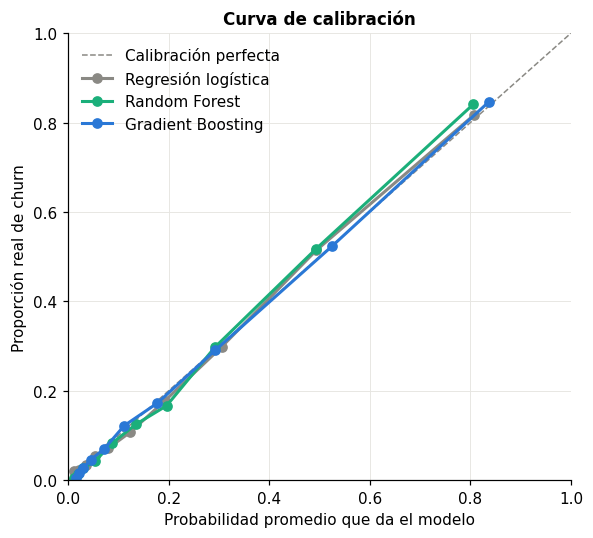

In [75]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=GRIS, ls='--', lw=1, label='Calibración perfecta')
for nombre in ['Regresión logística', 'Random Forest', 'Gradient Boosting']:
    real, predicho = calibration_curve(y_test, prob_test[nombre], n_bins=10, strategy='quantile')
    ax.plot(predicho, real, marker='o', ms=6, lw=2, color=COLOR_MODELO[nombre], label=nombre)
ax.set_xlabel('Probabilidad promedio que da el modelo'); ax.set_ylabel('Proporción real de churn')
ax.set_title('Curva de calibración'); ax.legend(frameon=False)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

In [76]:
#guardamos el mejor modelo
VERSION = '1.0.0'
NOMBRE_ELEGIDO = 'Gradient Boosting'
modelo_final = modelos[NOMBRE_ELEGIDO]
_, umbral_contacto = marcar_contacto(prob_test[NOMBRE_ELEGIDO])

os.makedirs('modelos', exist_ok=True)
joblib.dump(modelo_final, f'modelos/modelo_churn_v{VERSION}.joblib')

info = {
    'version': VERSION,
    'algoritmo': NOMBRE_ELEGIDO,
    'fecha_entrenamiento': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M'),
    'hiperparametros': {k.replace('modelo__', ''): (v if isinstance(v, (str, type(None))) else float(v))
                        for k, v in busqueda_gb.best_params_.items()},
    'columnas_entrada': COLUMNAS_ENTRADA,
    'capacidad_contacto': CAPACIDAD,
    'umbral_contacto': float(umbral_contacto),
    'metricas_evaluacion': {m: float(comparacion.loc[NOMBRE_ELEGIDO, m]) for m in ['AUC', 'Captura 20%', 'Acierto lista 20%']},
    'intervalos_95': {m: [float(intervalos.loc[(NOMBRE_ELEGIDO, m), 'límite inferior']),
                          float(intervalos.loc[(NOMBRE_ELEGIDO, m), 'límite superior'])]
                      for m in ['AUC', 'Captura 20%', 'Acierto lista 20%']},
    'clientes_entrenamiento': int(len(train)),
    'tasa_churn_entrenamiento': float(y_train.mean()),
}
with open(f'modelos/modelo_churn_v{VERSION}.json', 'w') as f:
    json.dump(info, f, indent=2, ensure_ascii=False)

print(f'Guardado: modelos/modelo_churn_v{VERSION}.joblib ({os.path.getsize(f"modelos/modelo_churn_v{VERSION}.joblib") / 1e6:.1f} MB)')
print(json.dumps(info, indent=2, ensure_ascii=False))

Guardado: modelos/modelo_churn_v1.0.0.joblib (0.6 MB)
{
  "version": "1.0.0",
  "algoritmo": "Gradient Boosting",
  "fecha_entrenamiento": "2026-11-21 22:29",
  "hiperparametros": {
    "learning_rate": 0.03933964846554668,
    "max_depth": 4.0,
    "min_samples_leaf": 169.0,
    "n_estimators": 357.0,
    "subsample": 0.8887995089067299
  },
  "columnas_entrada": [
    "CreditScore",
    "Geography",
    "Gender",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary"
  ],
  "capacidad_contacto": 0.2,
  "umbral_contacto": 0.3829956287899421,
  "metricas_evaluacion": {
    "AUC": 0.890428725663821,
    "Captura 20%": 0.6464501751034702,
    "Acierto lista 20%": 0.6845920431557654
  },
  "intervalos_95": {
    "AUC": [
      0.885561600308301,
      0.8947536237887712
    ],
    "Captura 20%": [
      0.6359089539089308,
      0.655654505189301
    ],
    "Acierto lista 20%": [
      0.6705116318273769,
      0.699098111

In [77]:
# Prueba: cargar el modelo guardado y predecir el cliente de ejemplo del punto 2, como hará la aplicación
modelo_cargado = joblib.load(f'modelos/modelo_churn_v{VERSION}.joblib')
prob = modelo_cargado.predict_proba(cliente_nuevo)[0, 1]
print(f'Probabilidad de churn: {prob:.1%} -> {"CONTACTAR" if prob >= umbral_contacto else "no contactar"}')

Probabilidad de churn: 92.7% -> CONTACTAR


In [78]:
import sklearn
print(sklearn.__version__)

1.6.1
